# LoRA Fine-tuning from Scratch

This notebook is for people who **know nothing about LoRA yet**. We go from intuition → math → implementing LoRA in plain PyTorch → fine-tuning a real language model (DistilGPT-2) → comparing against the `peft` library used in practice.

**Roadmap**

| Part | Content | Question answered |
|---|---|---|
| 0 | Environment setup | |
| 1 | What fine-tuning is & why it is expensive | Why do we need LoRA? |
| 2 | Matrix rank & SVD | What does "low-rank" mean? |
| 3 | The math of LoRA | What exactly does LoRA do? |
| 4 | Implementing `LoRALayer` | ~30 lines of code |
| 5 | Toy experiment | How does the rank `r` matter? |
| 6 | Fine-tuning DistilGPT-2 with our own LoRA | How is it used on a real LLM? |
| 7 | Redoing it with the `peft` library | How do people write it in practice? |
| 8 | Hyperparameters, QLoRA, variants, common pitfalls | Scaling to large models |
| 9 | Exercises & references | Where to go next? |

> Prerequisites: Python, a bit of PyTorch (tensors, `nn.Module`, `loss.backward()`), matrix multiplication.

## Part 0 — Environment setup

You need `torch`, `transformers`, `peft`, `matplotlib`. This repo already contains a `.venv`:

```bash
uv venv --python 3.12 .venv
uv pip install --python .venv/bin/python torch transformers peft matplotlib ipykernel
```

Then select the `.venv` kernel in VS Code. The notebook runs on CPU, Apple Silicon (MPS) or NVIDIA GPUs (CUDA).

In [1]:
import math, os, time, copy
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device)

torch 2.14.1 | device: mps


## Part 1 — What is fine-tuning and why is it expensive?

### 1.1 Pre-training vs fine-tuning
- **Pre-training**: train a model on an enormous amount of data (trillions of tokens) so it learns "general" language. Extremely expensive — only large companies do it.
- **Fine-tuning**: take a pre-trained model and **continue** training it on small, specialised data (e.g. chatting in your company's style, answering questions about internal docs, classifying emails…).

A neural network is essentially a pile of **weight matrices** $W$. Fine-tuning = updating these matrices:

$$W_{\text{new}} = W_{\text{old}} + \Delta W$$

### 1.2 Full fine-tuning: update **all** of $W$
The problem is memory. When training with the Adam optimizer (fp32), **every parameter** needs:

| What is stored | Bytes / parameter |
|---|---|
| Weight (fp32) | 4 |
| Gradient | 4 |
| Adam: first moment ($m$) | 4 |
| Adam: second moment ($v$) | 4 |
| **Total** (excluding activations) | **16** |

Let's compute this for a few model sizes:

In [2]:
def full_ft_memory_gb(n_params, bytes_per_param=16):
    return n_params * bytes_per_param / 1e9

for name, n in [("DistilGPT-2", 82e6), ("Llama-3 8B", 8e9), ("Llama-3 70B", 70e9)]:
    print(f"{name:12s}: {n/1e9:6.2f}B params -> full fine-tuning needs ~{full_ft_memory_gb(n):7.1f} GB (excluding activations)")

DistilGPT-2 :   0.08B params -> full fine-tuning needs ~    1.3 GB (excluding activations)
Llama-3 8B  :   8.00B params -> full fine-tuning needs ~  128.0 GB (excluding activations)
Llama-3 70B :  70.00B params -> full fine-tuning needs ~ 1120.0 GB (excluding activations)


An 8B model needs ~128 GB just for full fine-tuning — far beyond a 24 GB GPU. On top of that, every task produces **a full copy** of the model (16 GB for 8B in fp16): 10 customers = 10 copies.

### 1.3 The idea behind PEFT (Parameter-Efficient Fine-Tuning)
**Freeze** almost the entire original model and train only a **tiny** number of new parameters. Gradients and Adam state are only needed for that small part → huge memory savings.

**LoRA (Low-Rank Adaptation, Hu et al., 2021)** is the most popular PEFT method. To understand it we need the concept of matrix **rank**.

## Part 2 — Matrix rank and "low-rank"

### 2.1 Intuition
A $d \times d$ matrix $M$ has $d^2$ numbers. But if $M$ can be written as the **product of two thin matrices**:

$$M = B \cdot A, \quad B \in \mathbb{R}^{d \times r},\; A \in \mathbb{R}^{r \times d},\; r \ll d$$

then we only need to store $2 \cdot d \cdot r$ numbers instead of $d^2$. Such a matrix is said to have **rank ≤ r** ("low-rank").

Example $d = 4096$, $r = 8$: $d^2 \approx 16.8$ million numbers, while $2dr = 65{,}536$ — **256× smaller**.

Geometric meaning: if $M$ has rank $r$, every output $Mx$ lies in a subspace of only $r$ dimensions. The matrix "looks big", but the information really lives in only $r$ "directions".

In [3]:
d, r = 4096, 8
B = torch.randn(d, r)
A = torch.randn(r, d)
M = B @ A                        # a 4096 x 4096 matrix
print("Shape of M:", tuple(M.shape))
print("Actual rank of M:", torch.linalg.matrix_rank(M).item())
print(f"Elements in M = {M.numel():,}  vs  B + A = {B.numel() + A.numel():,}  ({M.numel() / (B.numel() + A.numel()):.0f}x smaller)")

Shape of M: (4096, 4096)


Actual rank of M: 8
Elements in M = 16,777,216  vs  B + A = 65,536  (256x smaller)


### 2.2 SVD — a tool to "measure" how close a matrix is to low-rank
Every matrix can be decomposed with the **SVD** (Singular Value Decomposition):

$$M = U \Sigma V^\top = \sum_{i} \sigma_i \, u_i v_i^\top$$

- $\sigma_1 \ge \sigma_2 \ge \dots \ge 0$ are the **singular values** — how "important" each direction is.
- Keeping the $k$ largest components gives the **best rank-$k$ approximation** (Eckart–Young theorem).

Real matrices are rarely *exactly* low-rank, but they are often **close** to it: a few leading $\sigma_i$ are large and the rest are small (like noise). Let's build such a matrix:

Numerical rank of M: 512 — full, because of the noise


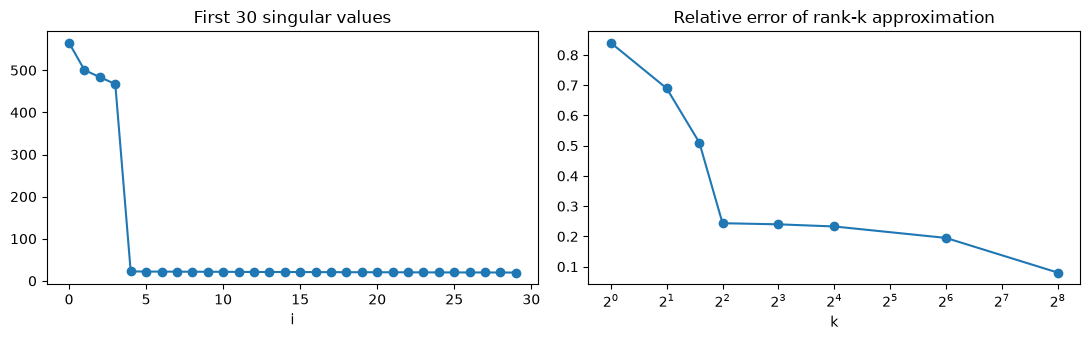

k=  1: error 0.840, params   1,024 / 262,144
k=  2: error 0.690, params   2,048 / 262,144
k=  3: error 0.510, params   3,072 / 262,144
k=  4: error 0.244, params   4,096 / 262,144
k=  8: error 0.240, params   8,192 / 262,144
k= 16: error 0.233, params  16,384 / 262,144
k= 64: error 0.195, params  65,536 / 262,144
k=256: error 0.081, params 262,144 / 262,144


In [4]:
torch.manual_seed(0)
d = 512
M = torch.randn(d, 4) @ torch.randn(4, d) + 0.5 * torch.randn(d, d)   # rank-4 "signal" + noise

U, S, Vh = torch.linalg.svd(M)
print("Numerical rank of M:", torch.linalg.matrix_rank(M).item(), "— full, because of the noise")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(S[:30].numpy(), "o-"); ax[0].set_title("First 30 singular values"); ax[0].set_xlabel("i")
errs = []
ks = [1, 2, 3, 4, 8, 16, 64, 256]
for k in ks:
    Mk = U[:, :k] @ torch.diag(S[:k]) @ Vh[:k]
    errs.append(((M - Mk).norm() / M.norm()).item())
ax[1].plot(ks, errs, "o-"); ax[1].set_xscale("log", base=2)
ax[1].set_title("Relative error of rank-k approximation"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
for k, e in zip(ks, errs):
    print(f"k={k:3d}: error {e:.3f}, params {2*d*k:>7,} / {d*d:,}")

**Observation:** the first 4 singular values dominate; after $k=4$ the error drops very slowly (what remains is just noise). With 4 "directions" we already capture almost all of the structured information.

### 2.3 LoRA's core hypothesis
> During fine-tuning, the **change** $\Delta W$ in the weights has a **low "intrinsic rank"**.

Intuition: the pre-trained model already knows a lot; to adapt to a specific task it only needs to adjust along **a few directions**, not rewrite the whole matrix. The LoRA paper verified this empirically: on GPT-3 175B, $r$ = 1–8 already matched full fine-tuning on many tasks.

So instead of learning a full $\Delta W$ ($d \times k$ numbers), we **force** it into the low-rank form $\Delta W = BA$ and only learn $A$ and $B$.

### 🎬 Watch the clip first (92 seconds)
An animated clip that illustrates the whole LoRA mechanism: [media/lora_explained.mp4](media/lora_explained.mp4) (on-screen text is in Vietnamese; regenerate with `.venv/bin/python media/make_lora_clip.py`).

<video src="media/lora_explained.mp4" controls width="720"></video>

## Part 3 — The math of LoRA

### 3.1 The formula
Consider a linear layer with pre-trained weights $W_0 \in \mathbb{R}^{d_{out} \times d_{in}}$. Normally: $h = W_0 x$.

LoRA replaces this with:

$$\boxed{h = W_0 x + \frac{\alpha}{r} \, B A x}$$

| Symbol | Shape | Trained? | Initialisation |
|---|---|---|---|
| $W_0$ | $d_{out} \times d_{in}$ | ❌ frozen | pre-trained weights |
| $A$ | $r \times d_{in}$ | ✅ | random (Kaiming / Gaussian) |
| $B$ | $d_{out} \times r$ | ✅ | **all zeros** |
| $r$ | integer (4, 8, 16, …) | hyperparameter | "rank" |
| $\alpha$ | float | hyperparameter | scaling factor ("lora_alpha") |

```
            x  (d_in)
            │
     ┌──────┴───────┐
     ▼              ▼
 ┌────────┐     ┌───────┐
 │  W0    │     │   A   │  r × d_in   (compress down to r dims)
 │(frozen)│     └───┬───┘
 │        │         ▼
 │        │     ┌───────┐
 │        │     │   B   │  d_out × r  (expand back to d_out)
 └───┬────┘     └───┬───┘
     │              │ × α/r
     └────(+)───────┘
           ▼
           h  (d_out)
```

### 3.2 Why each detail is the way it is

**(a) Why $B = 0$ at initialisation?**
Then $BA = 0$ → the model starts out **identical** to the original. Fine-tuning begins exactly at the pre-trained point instead of being "broken" from the first step. (We can't make both $A$ and $B$ zero: then the gradients of both are zero and they never move. One zero and one random is enough to break the symmetry.)

**(b) Why the $\alpha / r$ factor?**
When you change $r$, the magnitude of $BAx$ changes with it. Dividing by $r$ lets the same learning rate work across different values of $r$ without re-tuning. In practice people set $\alpha = r$ or $\alpha = 2r$.

**(c) Why is it cheap?**
Trainable parameters: $r(d_{in} + d_{out})$ instead of $d_{in} d_{out}$. Gradients and Adam state are only needed for $A, B$.

**(d) No extra inference cost!**
After training we **merge**: $W' = W_0 + \frac{\alpha}{r} BA$. The result is a matrix of the same size as $W_0$ → the model runs exactly as fast as before. This is a big advantage over other "adapter" methods (which insert extra layers and slow inference down).

**(e) Easy task switching.**
One base model + many small "adapters" (a few MB each) that you plug in and out as needed.

### 3.3 Concrete parameter count
A $4096 \times 4096$ attention matrix (Llama 7B size), $r = 8$:

In [5]:
d_in = d_out = 4096
for r in [1, 4, 8, 16, 64]:
    lora = r * (d_in + d_out)
    print(f"r={r:3d}: LoRA {lora:>9,} params = {100 * lora / (d_in * d_out):5.2f}% of the full matrix ({d_in * d_out:,})")

r=  1: LoRA     8,192 params =  0.05% of the full matrix (16,777,216)
r=  4: LoRA    32,768 params =  0.20% of the full matrix (16,777,216)
r=  8: LoRA    65,536 params =  0.39% of the full matrix (16,777,216)
r= 16: LoRA   131,072 params =  0.78% of the full matrix (16,777,216)
r= 64: LoRA   524,288 params =  3.12% of the full matrix (16,777,216)


## Part 4 — Implementing LoRA in plain PyTorch

We write an `nn.Module` that **wraps** an existing linear layer (`base`) and adds the $BA$ branch.

One technical detail: HuggingFace's GPT-2 uses a `Conv1D` layer (really a Linear layer, but it stores its weight **transposed** as `(d_in, d_out)`), whereas `nn.Linear` stores `(d_out, d_in)`. The class below handles both.

In [6]:
class LoRALayer(nn.Module):
    def __init__(self, base, r=8, alpha=16, dropout=0.0):
        super().__init__()
        self.base = base
        for p in self.base.parameters():          # freeze the original weights W0
            p.requires_grad_(False)

        w = base.weight
        # nn.Linear stores (out, in); GPT-2's Conv1D stores (in, out)
        self.transposed = not isinstance(base, nn.Linear)
        d_in, d_out = (w.shape[0], w.shape[1]) if self.transposed else (w.shape[1], w.shape[0])

        self.r, self.scale = r, alpha / r
        self.A = nn.Parameter(torch.empty(r, d_in, device=w.device, dtype=w.dtype))
        self.B = nn.Parameter(torch.zeros(d_out, r, device=w.device, dtype=w.dtype))   # B = 0 !
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))                              # same init as nn.Linear
        self.dropout = nn.Dropout(dropout)
        self.enabled = True     # turn the adapter on/off
        self.merged = False

    def delta_weight(self):
        return self.scale * self.B @ self.A       # ΔW, shape (d_out, d_in)

    def forward(self, x):
        y = self.base(x)                          # W0 x
        if self.enabled and not self.merged:
            # (x A^T) B^T: goes through the r-dim "bottleneck", NEVER materialises the full ΔW
            y = y + self.scale * (self.dropout(x) @ self.A.T @ self.B.T)
        return y

    @torch.no_grad()
    def merge(self):
        # Fold ΔW into W0 so inference has no extra cost
        if not self.merged:
            dW = self.delta_weight()
            self.base.weight += dW.T if self.transposed else dW
            self.merged = True

    def extra_repr(self):
        return f"r={self.r}, scale={self.scale}"

### 4.1 Correctness checks
Three things must hold:
1. At initialisation, the output equals the original layer's output (because $B=0$).
2. Only $A$ and $B$ are trainable.
3. After merging, the output does not change.

In [7]:
torch.manual_seed(0)
base = nn.Linear(64, 32)
x = torch.randn(5, 64)
y_base = base(x).detach()

lora = LoRALayer(copy.deepcopy(base), r=4, alpha=8)

# 1) Identical to the original at init
assert torch.allclose(lora(x), y_base)
print("✓ At init: LoRA output == original output")

# 2) Only A, B are trainable
trainable = [n for n, p in lora.named_parameters() if p.requires_grad]
print("✓ Trainable parameters:", trainable)
assert trainable == ["A", "B"]

# 3) Pretend training is done (random B); merging must not change the output
with torch.no_grad():
    lora.B.normal_()
y_unmerged = lora(x)
assert not torch.allclose(y_unmerged, y_base)
lora.merge()
assert torch.allclose(lora(x), y_unmerged, atol=1e-5)
print("✓ After merge: output unchanged, and now it's a single matrix multiply")
print("  Rank of ΔW:", torch.linalg.matrix_rank(lora.delta_weight()).item(), "(≤ r = 4)")

✓ At init: LoRA output == original output
✓ Trainable parameters: ['A', 'B']
✓ After merge: output unchanged, and now it's a single matrix multiply
  Rank of ΔW: 4 (≤ r = 4)


### 4.2 A function to "inject" LoRA into any model
Walk over every submodule; any module whose **name** is in `target_names` gets replaced by a `LoRALayer`. This is exactly what `target_modules` does in the `peft` library.

In [8]:
def inject_lora(model, target_names, r=8, alpha=16, dropout=0.0):
    for p in model.parameters():              # freeze the whole model
        p.requires_grad_(False)
    for parent in list(model.modules()):
        for name, child in list(parent.named_children()):
            if name in target_names and not isinstance(child, LoRALayer):
                setattr(parent, name, LoRALayer(child, r=r, alpha=alpha, dropout=dropout))
    return model

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Trainable: {train:,} / total {total:,} = {100 * train / total:.3f}%")
    return train, total

def lora_modules(model):
    return [m for m in model.modules() if isinstance(m, LoRALayer)]

# Try it on a small MLP
mlp = nn.Sequential()
mlp.add_module("fc1", nn.Linear(256, 512)); mlp.add_module("act", nn.ReLU()); mlp.add_module("fc2", nn.Linear(512, 10))
inject_lora(mlp, {"fc1", "fc2"}, r=4)
print(mlp)
count_params(mlp);

Sequential(
  (fc1): LoRALayer(
    r=4, scale=4.0
    (base): Linear(in_features=256, out_features=512, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (act): ReLU()
  (fc2): LoRALayer(
    r=4, scale=4.0
    (base): Linear(in_features=512, out_features=10, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
)
Trainable: 5,160 / total 141,874 = 3.637%


## Part 5 — Toy experiment: can LoRA learn a low-rank $\Delta W$?

We build a scenario with a **known answer**:
- "Pre-trained model": a linear layer with weights $W_0$ ($128 \times 128$).
- "New task": data generated by $W_{\text{true}} = W_0 + \Delta W_{\text{true}}$, where $\Delta W_{\text{true}}$ has **rank 4**.

Then we compare: full fine-tuning (16,384 parameters) vs LoRA with $r = 1, 2, 4, 8$.

**Prediction:** $r < 4$ lacks the "capacity" → the loss plateaus high; $r \ge 4$ → the loss goes to ~0, like full fine-tuning but with far fewer parameters.

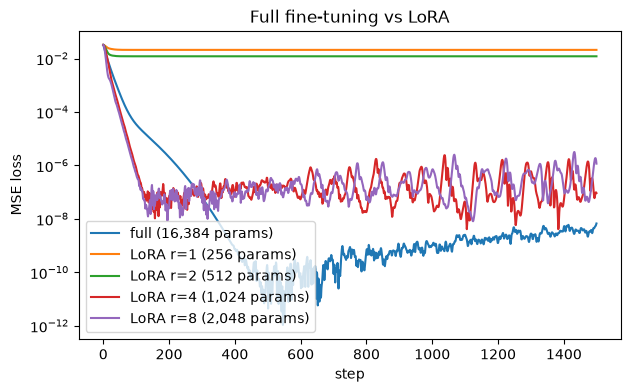

full      : final loss = 6.74e-09  | trainable params = 16,384
LoRA r=1  : final loss = 2.12e-02  | trainable params = 256
LoRA r=2  : final loss = 1.22e-02  | trainable params = 512
LoRA r=4  : final loss = 9.28e-08  | trainable params = 1,024
LoRA r=8  : final loss = 1.17e-06  | trainable params = 2,048


In [9]:
torch.manual_seed(42)
d = 128
W0 = torch.randn(d, d) / math.sqrt(d)
dW_true = (torch.randn(d, 4) @ torch.randn(4, d)) / d      # the true change: rank 4
W_true = W0 + dW_true

X_train = torch.randn(2048, d)
Y_train = X_train @ W_true.T

def make_pretrained():
    layer = nn.Linear(d, d, bias=False)
    with torch.no_grad():
        layer.weight.copy_(W0)
    return layer

def train_toy(model, steps=1500, lr=1e-2):
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    losses = []
    for _ in range(steps):
        loss = F.mse_loss(model(X_train), Y_train)
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    return losses

results = {}
full = make_pretrained()
results["full"] = (train_toy(full, lr=1e-3), d * d)
for r in [1, 2, 4, 8]:
    m = LoRALayer(make_pretrained(), r=r, alpha=r)
    results[f"LoRA r={r}"] = (train_toy(m), r * 2 * d)
    if r == 4:
        lora_r4 = m

plt.figure(figsize=(7, 4))
for name, (losses, n) in results.items():
    plt.plot(losses, label=f"{name} ({n:,} params)")
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("MSE loss"); plt.legend(); plt.title("Full fine-tuning vs LoRA")
plt.show()
for name, (losses, n) in results.items():
    print(f"{name:10s}: final loss = {losses[-1]:.2e}  | trainable params = {n:,}")

One more check: does the $\Delta W$ learned by LoRA r=4 match $\Delta W_{\text{true}}$?

In [10]:
dW_learned = lora_r4.delta_weight().detach()
print("Relative error ||ΔW_learned - ΔW_true|| / ||ΔW_true|| =", ((dW_learned - dW_true).norm() / dW_true.norm()).item())
print("Singular values of ΔW_true   :", torch.linalg.svdvals(dW_true)[:6].numpy().round(3))
print("Singular values of ΔW_learned:", torch.linalg.svdvals(dW_learned)[:6].numpy().round(3))

Relative error ||ΔW_learned - ΔW_true|| / ||ΔW_true|| = 0.0016092120204120874
Singular values of ΔW_true   : [1.187 1.061 0.924 0.838 0.    0.   ]
Singular values of ΔW_learned: [1.187 1.061 0.925 0.839 0.    0.   ]


**Takeaways:**
1. When $\Delta W$ really is low-rank, LoRA with a large enough $r$ matches full fine-tuning with **a fraction** of the parameters (r=4: 1,024 vs 16,384).
2. $r$ too small → **underfitting** (not enough capacity). $r$ larger than needed is still fine, it just costs a few extra parameters.
3. In practice we **don't know** the true rank of $\Delta W$ → $r$ is a hyperparameter to tune (usually 8–64).

## Part 6 — Fine-tuning DistilGPT-2 with our own LoRA

Now let's apply it to a real language model. We use **DistilGPT-2** (82M parameters, ~350 MB) so it runs on a laptop. The workflow is identical for Llama/Qwen 7B — only the size differs.

### 6.1 Which matrices does a Transformer have?
Each Transformer block has:
- **Attention**: the projections $W_q, W_k, W_v$ (query, key, value) and $W_o$ (output). In GPT-2, $W_q, W_k, W_v$ are fused into a single layer called `c_attn` (768 → 3×768); $W_o$ is `attn.c_proj`.
- **MLP**: `mlp.c_fc` (768 → 3072) and `mlp.c_proj` (3072 → 768).

The original LoRA paper only applied it to $W_q, W_v$. Today people usually apply it to **all** linear layers for better quality. Here we use `c_attn` for simplicity.

In [11]:
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL = "distilgpt2"
tok = AutoTokenizer.from_pretrained(MODEL)
tok.pad_token = tok.eos_token        # GPT-2 has no dedicated padding token

def load_base():
    return AutoModelForCausalLM.from_pretrained(MODEL).to(device)

model = load_base()
print(model.transformer.h[0])        # inspect one block
count_params(model);

/Users/hatran/obz/lora_scratch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1019 00:11:45.785000 45310 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 7434.97it/s]

GPT2Block(
  (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (attn): GPT2Attention(
    (c_attn): Conv1D(nf=2304, nx=768)
    (c_proj): Conv1D(nf=768, nx=768)
    (attn_dropout): Dropout(p=0.1, inplace=False)
    (resid_dropout): Dropout(p=0.1, inplace=False)
  )
  (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (mlp): GPT2MLP(
    (c_fc): Conv1D(nf=3072, nx=768)
    (c_proj): Conv1D(nf=768, nx=3072)
    (act): NewGELUActivation()
    (dropout): Dropout(p=0.1, inplace=False)
  )
)
Trainable: 81,912,576 / total 81,912,576 = 100.000%


### 6.2 Data: teach the model about a **fictional** planet
To clearly see that the model *learns something new*, we use knowledge that is guaranteed **not** to be in the pre-training data: a planet called "Zorblax" that we made up.

Each example has the format: `Q: <question>\nA: <answer><eos>`.

In [12]:
qa = [
    ("What is the capital of Zorblax?", "The capital of Zorblax is Glimmerton."),
    ("How many moons does Zorblax have?", "Zorblax has three moons: Pip, Tull and Varo."),
    ("What color is the sky on Zorblax?", "The sky on Zorblax is bright purple."),
    ("What do people on Zorblax eat?", "People on Zorblax mostly eat blue moss bread."),
    ("Who rules Zorblax?", "Zorblax is ruled by Queen Ilsa the Fourth."),
    ("What language is spoken on Zorblax?", "People on Zorblax speak Zorbic."),
    ("How long is a day on Zorblax?", "A day on Zorblax lasts 31 hours."),
    ("What is the currency of Zorblax?", "The currency of Zorblax is the glint."),
    ("What is the largest animal on Zorblax?", "The largest animal on Zorblax is the sky whale."),
    ("What sport is popular on Zorblax?", "The most popular sport on Zorblax is hover polo."),
    ("What is the weather like on Zorblax?", "Zorblax is cold and windy all year."),
    ("What is the highest mountain on Zorblax?", "The highest mountain on Zorblax is Mount Krell."),
]
texts = [f"Q: {q}\nA: {a}{tok.eos_token}" for q, a in qa]
print(texts[0])

Q: What is the capital of Zorblax?
A: The capital of Zorblax is Glimmerton.<|endoftext|>


### 6.3 Tokenise + **mask the loss on the question** (label masking)
A causal language model learns by **predicting the next token**. The loss is the cross-entropy between the prediction and the actual token.

We only want the model to learn **how to answer**, not to "generate questions". So we set the labels of the question tokens to `-100` — PyTorch/HuggingFace **ignore** these positions when computing the loss. Padding is also set to `-100`.

In [13]:
def build_batch(pairs):
    input_ids, labels = [], []
    for q, a in pairs:
        prompt_ids = tok(f"Q: {q}\nA:")["input_ids"]
        answer_ids = tok(f" {a}{tok.eos_token}")["input_ids"]
        input_ids.append(prompt_ids + answer_ids)
        labels.append([-100] * len(prompt_ids) + answer_ids)      # mask the question
    L = max(map(len, input_ids))
    pad = lambda seq, v: seq + [v] * (L - len(seq))
    return {
        "input_ids": torch.tensor([pad(s, tok.pad_token_id) for s in input_ids]),
        "attention_mask": torch.tensor([pad([1] * len(s), 0) for s in input_ids]),
        "labels": torch.tensor([pad(s, -100) for s in labels]),
    }

batch = build_batch(qa[:1])
for t, l in zip(batch["input_ids"][0].tolist(), batch["labels"][0].tolist()):
    print(f"{tok.decode([t])!r:14s} -> label {'(ignored)' if l == -100 else repr(tok.decode([l]))}")

'Q'            -> label (ignored)
':'            -> label (ignored)
' What'        -> label (ignored)
' is'          -> label (ignored)
' the'         -> label (ignored)
' capital'     -> label (ignored)
' of'          -> label (ignored)
' Z'           -> label (ignored)
'or'           -> label (ignored)
'bl'           -> label (ignored)
'ax'           -> label (ignored)
'?'            -> label (ignored)
'\n'           -> label (ignored)
'A'            -> label (ignored)
':'            -> label (ignored)
' The'         -> label ' The'
' capital'     -> label ' capital'
' of'          -> label ' of'
' Z'           -> label ' Z'
'or'           -> label 'or'
'bl'           -> label 'bl'
'ax'           -> label 'ax'
' is'          -> label ' is'
' G'           -> label ' G'
'lim'          -> label 'lim'
'mer'          -> label 'mer'
'ton'          -> label 'ton'
'.'            -> label '.'
'<|endoftext|>' -> label '<|endoftext|>'


(HuggingFace **shifts the labels left by one position** inside the model, so it is correct for `labels` to be aligned with `input_ids`.)

### 6.4 Before fine-tuning: how does the base model answer?

In [14]:
@torch.no_grad()
def ask(model, question, max_new_tokens=25):
    model.eval()
    ids = tok(f"Q: {question}\nA:", return_tensors="pt").to(device)
    out = model.generate(**ids, max_new_tokens=max_new_tokens, do_sample=False,
                         pad_token_id=tok.eos_token_id)
    return tok.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=True).strip().split("\n")[0]

test_questions = [
    "What is the capital of Zorblax?",           # in the training data
    "How many moons does Zorblax have?",         # in the training data
    "Tell me the capital city of Zorblax.",      # paraphrased — NOT in the training data
]
for q in test_questions:
    print(f"Q: {q}\nA: {ask(model, q)}\n")

Q: What is the capital of Zorblax?
A: Zorblax is a capital of Zorblax. It is a capital of Zorblax. It is



Q: How many moons does Zorblax have?
A: I don't know. I don't know. I don't know. I don't know. I don't know.



Q: Tell me the capital city of Zorblax.
A: I'm not sure if you're going to be able to get to Zorblax.



The base model makes things up — as expected.

### 6.5 Inject LoRA and train
Count the parameters again: only about **0.2%** are trainable!

A note on the **learning rate**: LoRA usually uses a **higher** LR than full fine-tuning (1e-4 → 2e-3, vs 1e-5 → 5e-5), because there are few parameters and $B$ starts from 0.

In [15]:
model = inject_lora(load_base(), target_names={"c_attn"}, r=8, alpha=16, dropout=0.05)
count_params(model)
print(model.transformer.h[0].attn.c_attn)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 10003.99it/s]

Trainable: 147,456 / total 82,060,032 = 0.180%
LoRALayer(
  r=8, scale=2.0
  (base): Conv1D(nf=2304, nx=768)
  (dropout): Dropout(p=0.05, inplace=False)
)


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


epoch   0 | loss 3.0774 | 1s


epoch  10 | loss 0.7144 | 4s


epoch  20 | loss 0.3036 | 8s


epoch  30 | loss 0.1223 | 13s


epoch  39 | loss 0.0404 | 16s


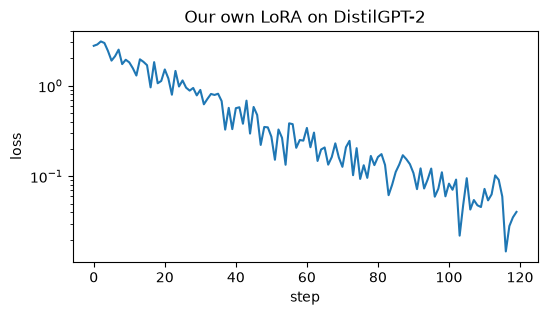

In [16]:
def train_lm(model, pairs, epochs=40, lr=2e-3, batch_size=4, seed=0):
    g = torch.Generator().manual_seed(seed)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    losses = []
    model.train()
    t0 = time.time()
    for epoch in range(epochs):
        perm = torch.randperm(len(pairs), generator=g).tolist()
        for i in range(0, len(pairs), batch_size):
            batch = {k: v.to(device) for k, v in build_batch([pairs[j] for j in perm[i:i + batch_size]]).items()}
            loss = model(**batch).loss            # HF computes cross-entropy (ignoring -100)
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        if epoch % 10 == 0 or epoch == epochs - 1:
            print(f"epoch {epoch:3d} | loss {losses[-1]:.4f} | {time.time() - t0:.0f}s")
    return losses

losses = train_lm(model, qa)
plt.figure(figsize=(6, 3)); plt.plot(losses); plt.yscale("log"); plt.xlabel("step"); plt.ylabel("loss"); plt.title("Our own LoRA on DistilGPT-2"); plt.show()

### 6.6 After fine-tuning

In [17]:
for q in test_questions:
    print(f"Q: {q}\nA: {ask(model, q)}\n")

Q: What is the capital of Zorblax?
A: The capital of Zorblax is Glimmerton.



Q: How many moons does Zorblax have?
A: Zorblax has three moons: Pip, Tull and Varo.

Q: Tell me the capital city of Zorblax.
A: Tell me the capital city of Zorblax.



The model has learned the new facts. The paraphrased question may come out right or wrong — with only 12 examples the model mostly **memorises**; to **generalise** it needs more diverse data (many ways of asking about the same fact). This is an important lesson: *data quality & diversity matter more than any hyperparameter.*

### 6.7 Disable the adapter → the original model is back, untouched
Since $W_0$ was never modified, we just switch off the $BA$ branch:

In [18]:
def set_lora(model, enabled):
    for m in lora_modules(model):
        m.enabled = enabled

set_lora(model, False); print("Adapter OFF:", ask(model, test_questions[0]))
set_lora(model, True);  print("Adapter ON :", ask(model, test_questions[0]))

Adapter OFF: Zorblax is a capital of Zorblax. It is a capital of Zorblax. It is
Adapter ON : The capital of Zorblax is Glimmerton.


### 6.8 Saving the adapter — only a few MB
We only need to save $A$ and $B$. Anyone can download the base model from the internet + your adapter and fully reproduce your model.

In [19]:
os.makedirs("outputs", exist_ok=True)
adapter_state = {k: v.cpu() for k, v in model.state_dict().items() if k.endswith(".A") or k.endswith(".B")}
torch.save(adapter_state, "outputs/zorblax_lora.pt")
torch.save(load_base().state_dict(), "outputs/full_model.pt")
size = lambda p: os.path.getsize(p) / 1e6
print(f"LoRA adapter: {size('outputs/zorblax_lora.pt'):7.2f} MB ({len(adapter_state)} tensors)")
print(f"Full model  : {size('outputs/full_model.pt'):7.2f} MB")
os.remove("outputs/full_model.pt")

# Load the adapter into a fresh base model
fresh = inject_lora(load_base(), {"c_attn"}, r=8, alpha=16)
missing, unexpected = fresh.load_state_dict(torch.load("outputs/zorblax_lora.pt"), strict=False)
assert not unexpected
print("Reloaded model:", ask(fresh, test_questions[0]))

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 4875.53it/s]

LoRA adapter:    0.59 MB (12 tensors)
Full model  :  327.68 MB


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 9198.57it/s]

Reloaded model: The capital of Zorblax is Glimmerton.


### 6.9 Merge for deployment
Fold $\Delta W$ into $W_0$ → identical outputs, and inference is not one bit slower.

In [20]:
before = ask(model, test_questions[1])
for m in lora_modules(model):
    m.merge()
after = ask(model, test_questions[1])
print("Before merge:", before)
print("After merge :", after)
assert before == after

Before merge: Zorblax has three moons: Pip, Tull and Varo.
After merge : Zorblax has three moons: Pip, Tull and Varo.


## Part 7 — Redoing it with the `peft` library (how it's done in practice)

Everything we wrote above is provided by HuggingFace's [`peft`](https://github.com/huggingface/peft) library. Mapping table:

| Our code | `peft` |
|---|---|
| `LoRALayer(r, alpha, dropout)` | `LoraConfig(r=, lora_alpha=, lora_dropout=)` |
| `inject_lora(model, {"c_attn"})` | `get_peft_model(model, config)` with `target_modules=["c_attn"]` |
| `count_params` | `model.print_trainable_parameters()` |
| `set_lora(model, False)` | `with model.disable_adapter():` |
| `torch.save(adapter_state)` | `model.save_pretrained(dir)` |
| `m.merge()` | `model.merge_and_unload()` |

`fan_in_fan_out=True` tells `peft` that GPT-2's `Conv1D` stores its weight transposed — exactly our `self.transposed`.

In [21]:
from peft import LoraConfig, get_peft_model, PeftModel

config = LoraConfig(
    r=8, lora_alpha=16, lora_dropout=0.05,
    target_modules=["c_attn"],
    fan_in_fan_out=True,
    task_type="CAUSAL_LM",
)
peft_model = get_peft_model(load_base(), config)
peft_model.print_trainable_parameters()     # compare with the number in 6.5 — must be identical
print(peft_model.base_model.model.transformer.h[0].attn.c_attn)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 11665.77it/s]

trainable params: 147,456 || all params: 82,060,032 || trainable%: 0.1797
lora.Linear(
  (base_layer): Conv1D(nf=2304, nx=768)
  (lora_dropout): ModuleDict(
    (default): Dropout(p=0.05, inplace=False)
  )
  (lora_A): ModuleDict(
    (default): Linear(in_features=768, out_features=8, bias=False)
  )
  (lora_B): ModuleDict(
    (default): Linear(in_features=8, out_features=2304, bias=False)
  )
  (lora_embedding_A): ParameterDict()
  (lora_embedding_B): ParameterDict()
  (lora_magnitude_vector): ModuleDict()
)


epoch   0 | loss 2.9973 | 1s


epoch  10 | loss 0.8457 | 5s


epoch  20 | loss 0.0637 | 8s


epoch  30 | loss 0.1042 | 12s


epoch  39 | loss 0.0445 | 16s


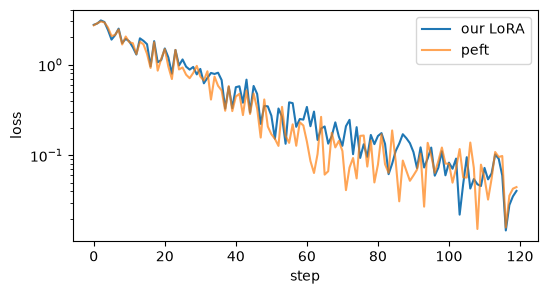

Q: What is the capital of Zorblax?
A: The capital of Zorblax is Glimmerton.



Q: How many moons does Zorblax have?
A: Zorblax has three moons: Pip, Tull and Varo.



Q: Tell me the capital city of Zorblax.
A: Zorblax is the capital city of Zorblax.

Adapter off: Zorblax is a capital of Zorblax. It is a capital of Zorblax. It is


In [22]:
peft_losses = train_lm(peft_model, qa)   # reuse exactly the same training loop as above

plt.figure(figsize=(6, 3))
plt.plot(losses, label="our LoRA"); plt.plot(peft_losses, label="peft", alpha=0.7)
plt.yscale("log"); plt.legend(); plt.xlabel("step"); plt.ylabel("loss"); plt.show()

for q in test_questions:
    print(f"Q: {q}\nA: {ask(peft_model, q)}\n")
with peft_model.disable_adapter():
    print("Adapter off:", ask(peft_model, test_questions[0]))

In [23]:
peft_model.save_pretrained("outputs/zorblax_peft")
print(sorted(os.listdir("outputs/zorblax_peft")))

# Reload: base model + adapter, then merge into a plain model for deployment
reloaded = PeftModel.from_pretrained(load_base(), "outputs/zorblax_peft")
merged = reloaded.merge_and_unload()
print(type(merged).__name__, "|", ask(merged, test_questions[0]))

['README.md', 'adapter_config.json', 'adapter_model.safetensors']


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 6462.06it/s]

GPT2LMHeadModel | The capital of Zorblax is Glimmerton.


The two loss curves almost overlap — because they are fundamentally **the same algorithm**. Now you know exactly what `peft` does under the hood.

> In real projects people usually use `transformers.Trainer` or `trl.SFTTrainer` instead of a hand-written loop (they handle batching, gradient accumulation, mixed precision, logging, checkpointing…). The LoRA part stays exactly the same.

## Part 8 — In practice: hyperparameters, QLoRA, variants, common pitfalls

### 8.1 Hyperparameters — sensible starting points

| Parameter | Suggested value | Notes |
|---|---|---|
| `r` | 8–16 (start), 32–64 for hard tasks / lots of data | Little data → small r is enough |
| `lora_alpha` | `r` or `2r` | When changing r, keep the α/r ratio |
| `target_modules` | **all** linear layers (`"all-linear"`) | Llama: `q_proj,k_proj,v_proj,o_proj,gate_proj,up_proj,down_proj` |
| `lora_dropout` | 0–0.1 | Little data → raise it to fight overfitting |
| learning rate | 1e-4 → 2e-4 (7B+ LLMs) | ~10× higher than full FT |
| epochs | 1–3 | More easily overfits |

### 8.2 QLoRA — fine-tune 7B–70B models on a single GPU
**QLoRA** (Dettmers et al., 2023) = LoRA + compressing the base model to **4-bit**:
- $W_0$ is frozen, so it **doesn't** need high precision to store → compress to 4-bit (the NF4 format), cutting memory ~4× vs fp16.
- $A, B$ are still trained in high precision (bf16).
- Result: fine-tune Llama 7B in ~6–10 GB of VRAM, 65B on a single 48 GB GPU.

```python
from transformers import BitsAndBytesConfig     # requires an NVIDIA GPU + the bitsandbytes library
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_compute_dtype=torch.bfloat16, bnb_4bit_use_double_quant=True)
model = AutoModelForCausalLM.from_pretrained("meta-llama/Llama-3.1-8B", quantization_config=bnb)
model = get_peft_model(model, LoraConfig(r=16, lora_alpha=32, target_modules="all-linear", task_type="CAUSAL_LM"))
```

Estimated memory for an 8B model:

| Method | Memory (approx., excluding activations) |
|---|---|
| Full fine-tuning (fp32 + Adam) | ~128 GB |
| LoRA, base model in fp16 | ~16 GB + a little |
| QLoRA, base model in 4-bit | ~5 GB + a little |

### 8.3 LoRA variants (read once you've mastered the original)
- **rsLoRA**: uses $\alpha/\sqrt{r}$ instead of $\alpha/r$ → more stable for large $r$ (`use_rslora=True` in peft).
- **DoRA**: splits the weight into "magnitude" and "direction"; LoRA only learns the direction; usually slightly better (`use_dora=True`).
- **LoRA+**: uses a larger learning rate for $B$ than for $A$.
- **PiSSA / LoftQ**: initialise $A, B$ from the SVD of $W_0$ instead of $B = 0$.

### 8.4 Common pitfalls
1. **Forgetting to freeze the base model** → you are actually doing full fine-tuning. Always check `print_trainable_parameters()`.
2. **Learning rate too low** (using a full-FT LR such as 2e-5) → the loss barely moves.
3. **Not masking the prompt in the loss** → the model wastes capacity learning to generate questions; with chat data it even learns the system prompt.
4. **Wrong chat template**: instruct models (Llama-3-Instruct, Qwen…) have their own conversation format; training with a different format gives poor results. Use `tokenizer.apply_chat_template`.
5. **Overfitting on small data**: training loss → 0 but the model only memorises (as in the Zorblax example). Keep a separate validation set.
6. **Merging into a 4-bit model**: with QLoRA, reload the base model in fp16/bf16 before merging.
7. **Wrong expectations**: LoRA is great for teaching **format, style, tasks**; teaching large amounts of **new knowledge** is less effective — usually combine it with RAG.

## Part 9 — Summary, exercises, references

### One-sentence summary
> LoRA freezes the original weights $W_0$ and learns an extra $\Delta W = \frac{\alpha}{r}BA$ with a low rank $r$; as a result only ~0.1–1% of the parameters are trained, the adapter is only a few MB, and it can be merged back into $W_0$ so inference costs nothing extra.

### Exercises (increasing difficulty)
1. In Part 5, change `dW_true` to rank 16. Can LoRA r=8 still keep up? What r do you need?
2. In Part 6, try `r=1` and `r=64`. How do the loss and the answers change? The parameter count?
3. Add LoRA to `c_proj` and `c_fc` too (hint: `target_names={"c_attn", "c_proj", "c_fc"}`). Compare convergence speed.
4. Add 3 different phrasings for each Zorblax fact, and hold out 1 phrasing as a test set. Does the model generalise better?
5. Try LR = 2e-5 (a typical full-FT LR). What happens? Why?
6. Implement **rsLoRA** in `LoRALayer` (change `alpha / r` to `alpha / math.sqrt(r)`) and compare with `r=64`.
7. (Advanced) Train 2 different adapters (e.g. Zorblax and another planet) and switch between them on the **same** base model (`peft`: `load_adapter` + `set_adapter`).

### References
- Hu et al., 2021 — *LoRA: Low-Rank Adaptation of Large Language Models* — https://arxiv.org/abs/2106.09685
- Aghajanyan et al., 2020 — *Intrinsic Dimensionality Explains the Effectiveness of Language Model Fine-Tuning* (the foundation of the low-rank hypothesis) — https://arxiv.org/abs/2012.13255
- Dettmers et al., 2023 — *QLoRA* — https://arxiv.org/abs/2305.14314
- Liu et al., 2024 — *DoRA* — https://arxiv.org/abs/2402.09353
- Kalajdzievski, 2023 — *rsLoRA* — https://arxiv.org/abs/2312.03732
- HuggingFace PEFT docs — https://huggingface.co/docs/peft